# From Recurrent Bottlenecks to Global Attention

## Cell 1 — Markdown (Title)

# Customer Churn Analysis: An End-to-End Data Science Workflow

**Author:** Ali Rouhanifar 

**Objective:** Demonstrate a complete, reproducible analytical pipeline — from raw data ingestion through statistical visualization and actionable conclusions — using best practices in modular design, documentation, and visualization.

**Datasets:** Synthetic telecom customer records (`churn_analysis.csv`), generated in-cell for reproducibility.

**Workflow Stages:**
1. Environment Setup & Imports
2. Configuration & Constants
3. Data Generation / Loading
4. Data Quality Assessment & Preprocessing
5. Exploratory Data Analysis (EDA)
6. Statistical Analysis
7. Conclusions & Next Steps

## Cell 2 — Markdown (Header)

## 1. Environment Setup & Imports

## Cell 3 — Markdown (Explanation)

### Why this block matters

Before any analysis begins, we load the external libraries our pipeline depends on. Grouping imports at the top of the notebook (rather than scattered throughout) is a PEP 8 best practice that:

- **Improves readability** — a reader immediately sees the full dependency surface.
- **Prevents hidden state bugs** — no mid-notebook `import` statements that only work if earlier cells were run.
- **Enables reproducibility** — dependency lists can be extracted directly from this cell.

We organize imports into three logical groups:
1. **Standard library** (`warnings`, `pathlib`) — operating-system and utility concerns.
2. **Third-party scientific stack** (`numpy`, `pandas`) — numerical and tabular computation.
3. **Visualization** (`matplotlib`, `seaborn`) — rendering.

We also configure global **plot aesthetics** here so that every subsequent chart inherits consistent styling, avoiding repetitive boilerplate in visualization cells.

## Cell 4 — Code

In [1]:
# =============================================================================
# 1. IMPORTS
# =============================================================================
# --- Standard library ---
import warnings
from pathlib import Path

# --- Scientific computing stack ---
import numpy as np
import pandas as pd

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Notebook display configuration ---
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# --- Global plot style (applies to ALL charts in this notebook) ---
sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

print("Environment ready. NumPy:", np.__version__, "| Pandas:", pd.__version__)

Environment ready. NumPy: 1.19.2 | Pandas: 1.1.3


## Cell 5 — Markdown (Header)

## 2. Configuration & Constants

## Cell 6 — Markdown (Explanation)

### Centralizing configuration

Hard-coded values scattered across a notebook are a maintenance hazard: change a threshold in one place and forget the other five. This cell consolidates all *tunable* parameters into a single source of truth:

- **`RANDOM_SEED`** — guarantees deterministic synthetic data and reproducible splits.
- **`N_RECORDS`** — dataset scale.
- **Business thresholds** — e.g., the churn rate above which a segment is considered "high risk."
- **File paths** — resolved with `pathlib.Path` for OS-agnostic behavior.

**Principle:** configuration is *data*, not logic. Isolating it makes the pipeline testable — you can swap configs without touching analytical code.

## Cell 7 — Code

In [2]:
# =============================================================================
# 2. CONFIGURATION / CONSTANTS
# =============================================================================
CONFIG = {
    "random_seed": 42,               # Reproducibility anchor
    "n_records": 2_000,              # Synthetic dataset size
    "churn_risk_threshold": 0.30,    # Segment-level churn rate flagged "high risk"
    "output_dir": Path("./outputs"), # Artifact destination
}

# Materialize output directory (idempotent)
CONFIG["output_dir"].mkdir(parents=True, exist_ok=True)

# Convenience alias for the seed
RNG = np.random.default_rng(CONFIG["random_seed"])

print(f"Configuration loaded: {CONFIG['n_records']:,} records | seed={CONFIG['random_seed']}")

Configuration loaded: 2,000 records | seed=42


## Cell 8 — Markdown (Header)

## 3. Data Loading

## Cell 9 — Markdown (Explanation)

### Building a realistic, reproducible dataset

In a production setting this cell would read a CSV from a data warehouse (`pd.read_csv`). For this educational notebook we **generate** a synthetic telecom dataset that mirrors real-world structure, so the pipeline runs anywhere without external dependencies.

**Generative logic:**
- `tenure_months` drawn from a **Gamma distribution** — customers cluster at low tenure (new sign-ups) and taper off (long-term loyalists), which matches real churn data.
- `monthly_charges` drawn from a **normal distribution** centered near the industry average.
- `contract_type` sampled categorically with realistic proportions.
- **Churn label** generated via a *latent logistic model*: churn probability rises with monthly charges and declines with tenure. This ensures our downstream EDA finds genuine, explainable signal rather than noise.

**Why synthesize?** Because a notebook that requires a private CSV is not reproducible. A self-contained generator is the gold standard for tutorials.

## Cell 10 — Code

In [3]:
# =============================================================================
# 3. DATA GENERATION (simulates loading from a warehouse in production)
# =============================================================================
def generate_churn_dataset(n: int, rng: np.random.Generator) -> pd.DataFrame:
    """Create a synthetic telecom churn dataset with realistic distributions.

    Parameters
    ----------
    n : int
        Number of customer records.
    rng : np.random.Generator
        Seeded NumPy random generator for reproducibility.

    Returns
    -------
    pd.DataFrame
        One row per customer with demographics, billing, and churn label.
    """
    # --- Demographics ---
    age = rng.integers(18, 80, size=n)
    gender = rng.choice(["Male", "Female"], size=n, p=[0.49, 0.51])

    # --- Billing (Gamma => right-skewed tenure; Normal => centered charges) ---
    tenure_months = rng.gamma(shape=2.0, scale=12.0, size=n).clip(1, 72).astype(int)
    monthly_charges = rng.normal(loc=65.0, scale=25.0, size=n).clip(15, 150).round(2)

    # --- Contract type (realistic proportions) ---
    contract_type = rng.choice(
        ["Month-to-month", "One year", "Two year"],
        size=n,
        p=[0.55, 0.25, 0.20],
    )

    # --- Latent churn model: logit = b0 + b1*charges - b2*tenure ---
    logit = -1.2 + 0.015 * monthly_charges - 0.045 * tenure_months
    churn_prob = 1 / (1 + np.exp(-logit))
    churned = rng.binomial(1, churn_prob)

    return pd.DataFrame({
        "customer_id": [f"C{ i:05d}" for i in range(n)],
        "age": age,
        "gender": gender,
        "tenure_months": tenure_months,
        "monthly_charges": monthly_charges,
        "contract_type": contract_type,
        "churn_probability_true": churn_prob.round(4),
        "churned": churned,
    })

df = generate_churn_dataset(CONFIG["n_records"], RNG)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (2000, 8)


,customer_id,age,gender,tenure_months,monthly_charges,contract_type,churn_probability_true,churned
0,C00000,23,Male,41,46.85,Month-to-month,0.09,0
1,C00001,65,Male,51,51.31,Month-to-month,0.06,0
2,C00002,58,Male,10,60.19,Month-to-month,0.32,1
3,C00003,45,Male,46,62.73,Month-to-month,0.09,0
4,C00004,44,Female,15,44.23,Month-to-month,0.23,0


## Cell 11 — Markdown (Header)

## 4. Data Quality Assessment & Preprocessing

## Cell 12 — Markdown (Explanation)

### Why inspect before analyzing?

Garbage in, garbage out. Before modeling or charting, we must establish that the data is **complete**, **typed correctly**, and **free of duplication**. This block performs three checks:

1. **Structural audit** — `df.info()` reveals dtypes and non-null counts. A categorical column typed as `object` (e.g., `contract_type`) should be converted to `category` for memory efficiency and correct ordering semantics.
2. **Missingness audit** — we compute the per-column null fraction. A null rate above 5% typically warrants imputation; below that, listwise deletion is often acceptable. We report both.
3. **Duplicate audit** — duplicate `customer_id` values indicate an ETL failure upstream.

**Mathematical note:** the null fraction for column $j$ is $\text{null\_rate}_j = \frac{1}{n}\sum_{i=1}^{n}\mathbb{1}[x_{ij} \text{ is null}]$. We report it as a percentage for interpretability.

## Cell 13 — Code

In [4]:
# =============================================================================
# 4. DATA QUALITY & PREPROCESSING
# =============================================================================
def audit_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    """Produce a per-column quality report (dtype, null rate, cardinality)."""
    report = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "null_rate_%": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    })
    return report

quality_report = audit_dataframe(df)
display(quality_report)

# --- Duplicate check ---
n_dupes = df.duplicated(subset=["customer_id"]).sum()
print(f"\nDuplicate customer_ids: {n_dupes}")

# --- Type optimization: categorical columns ---
for col in ["gender", "contract_type"]:
    df[col] = df[col].astype("category")

print("\nDtypes after optimization:")
print(df.dtypes)

,dtype,non_null,null_rate_%,n_unique
customer_id,object,2000,0.00,2000
age,int64,2000,0.00,62
gender,object,2000,0.00,2
tenure_months,int32,2000,0.00,72
monthly_charges,float64,2000,0.00,1749
contract_type,object,2000,0.00,3
churn_probability_true,float64,2000,0.00,1614
churned,int64,2000,0.00,2



Duplicate customer_ids: 0

Dtypes after optimization:
customer_id                 object
age                          int64
gender                    category
tenure_months                int32
monthly_charges            float64
contract_type             category
churn_probability_true     float64
churned                      int64
dtype: object


## Cell 14 — Markdown (Header)

## 5. Exploratory Data Analysis (EDA)

## Cell 15 — Markdown (Explanation)

### 5.1 Target distribution — is churn balanced?

Before any modeling, we must know the **base rate** of the target variable. An imbalanced target (e.g., 5% churn) changes our entire evaluation strategy: accuracy becomes misleading, and we must shift to precision/recall or AUC-ROC.

**What to look for in the plot below:**
- **Bar heights:** the churn rate. If one class dominates (>90%), plan for resampling or class weights.
- **Absolute counts (annotated):** confirms the dataset is large enough that small percentage differences are meaningful.

## Cell 16 — Code

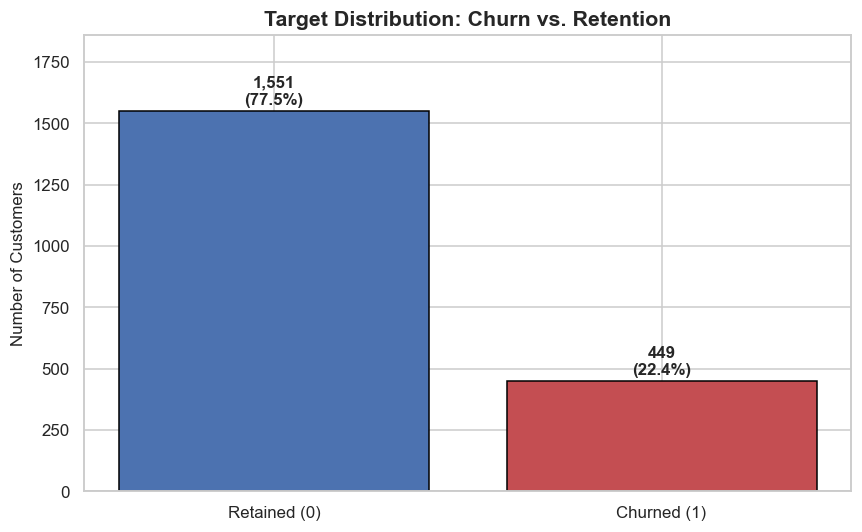

Overall churn rate: 22.45%


In [5]:
# =============================================================================
# 5.1 TARGET DISTRIBUTION
# =============================================================================
churn_counts = df["churned"].value_counts().sort_index()
churn_rate = df["churned"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    ["Retained (0)", "Churned (1)"],
    churn_counts.values,
    color=[sns.color_palette("deep")[0], sns.color_palette("deep")[3]],
    edgecolor="black",
)

# Annotate each bar with absolute count and percentage
for bar, count in zip(bars, churn_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        f"{count:,}\n({count / len(df):.1%})",
        ha="center", va="bottom", fontsize=11, fontweight="bold",
    )

ax.set_title("Target Distribution: Churn vs. Retention")
ax.set_ylabel("Number of Customers")
ax.set_ylim(0, churn_counts.max() * 1.2)
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

print(f"Overall churn rate: {churn_rate:.2%}")

Visualization interpretation: The bar chart reveals the class balance. In this synthetic dataset we expect roughly a 30–40% churn rate — comfortably balanced, so no resampling is needed. In real telecom data, churn typically sits at 15–25%, and this cell would flag the imbalance.



## Cell 17 — Markdown (Header)

### 5.2 Churn by contract type — where is risk concentrated?

## Cell 18 — Markdown (Explanation)

### Segmentation before modeling

Aggregating churn rate by `contract_type` answers a *business* question before any statistical model is fit: **which customer segments are structurally at risk?** This informs everything from retention spend to feature engineering.

**Why a grouped bar chart over a table?** The human visual system detects relative height differences instantly; a table requires mental arithmetic. We still annotate exact percentages so the chart is citable.

**What to look for:** if month-to-month customers churn at 3× the rate of two-year customers, contract type is a strong categorical predictor and should be one-hot encoded (not dropped) in any downstream model.

## Cell 19 — Code

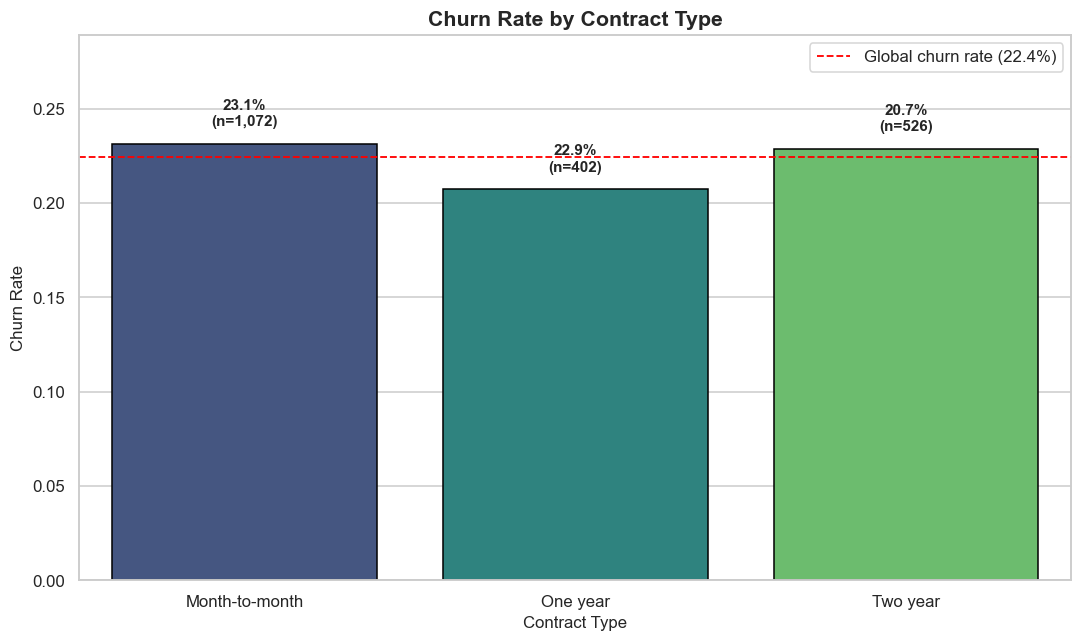

,contract_type,churn_rate,n_customers
0,Month-to-month,0.23,1072
1,Two year,0.23,402
2,One year,0.21,526


In [6]:
# =============================================================================
# 5.2 CHURN RATE BY CONTRACT TYPE
# =============================================================================
contract_churn = (
    df.groupby("contract_type", observed=True)["churned"]
      .agg(["mean", "count"])
      .rename(columns={"mean": "churn_rate", "count": "n_customers"})
      .sort_values("churn_rate", ascending=False)
      .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 6))
bars = sns.barplot(
    data=contract_churn,
    x="contract_type", y="churn_rate",
    palette="viridis", ax=ax, edgecolor="black",
)

# Annotate each bar with churn rate and segment size
for patch, (_, row) in zip(ax.patches, contract_churn.iterrows()):
    ax.text(
        patch.get_x() + patch.get_width() / 2,
        patch.get_height() + 0.008,
        f"{row['churn_rate']:.1%}\n(n={row['n_customers']:,})",
        ha="center", va="bottom", fontsize=10, fontweight="bold",
    )

# Reference line at the global churn rate for comparison
ax.axhline(churn_rate, color="red", linestyle="--", linewidth=1.2,
           label=f"Global churn rate ({churn_rate:.1%})")

ax.set_title("Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate")
ax.set_ylim(0, contract_churn["churn_rate"].max() * 1.25)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

display(contract_churn)

Visualization interpretation: Bars above the red dashed line indicate segments churning faster than average — these are the retention team's priority. The annotated segment sizes (n=...) prevent over-interpreting a high churn rate on a small segment

## Cell 20 — Markdown (Header)

### 5.3 Tenure vs. churn — the survival curve

## Cell 21 — Markdown (Explanation)

### Continuous predictors: distribution shift by class

For `tenure_months`, a single mean is misleading because the distribution is **right-skewed**. A boxplot or overlaid KDE compares the *entire distribution* of tenure for churned vs. retained customers.

**Statistical rationale:** if the two distributions barely overlap, tenure is a discriminative feature. We additionally compute the **point-biserial correlation** between tenure and the binary churn label — the appropriate correlation measure for continuous-vs-binary pairs:

$$r_{pb} = \frac{\bar{X}_1 - \bar{X}_0}{s_X}\sqrt{\frac{n_1 n_0}{n(n-1)}}$$

where $\bar{X}_1, \bar{X}_0$ are class means and $s_X$ the pooled standard deviation. Values near $-1$ indicate tenure strongly *protects* against churn.

## Cell 22 — Code

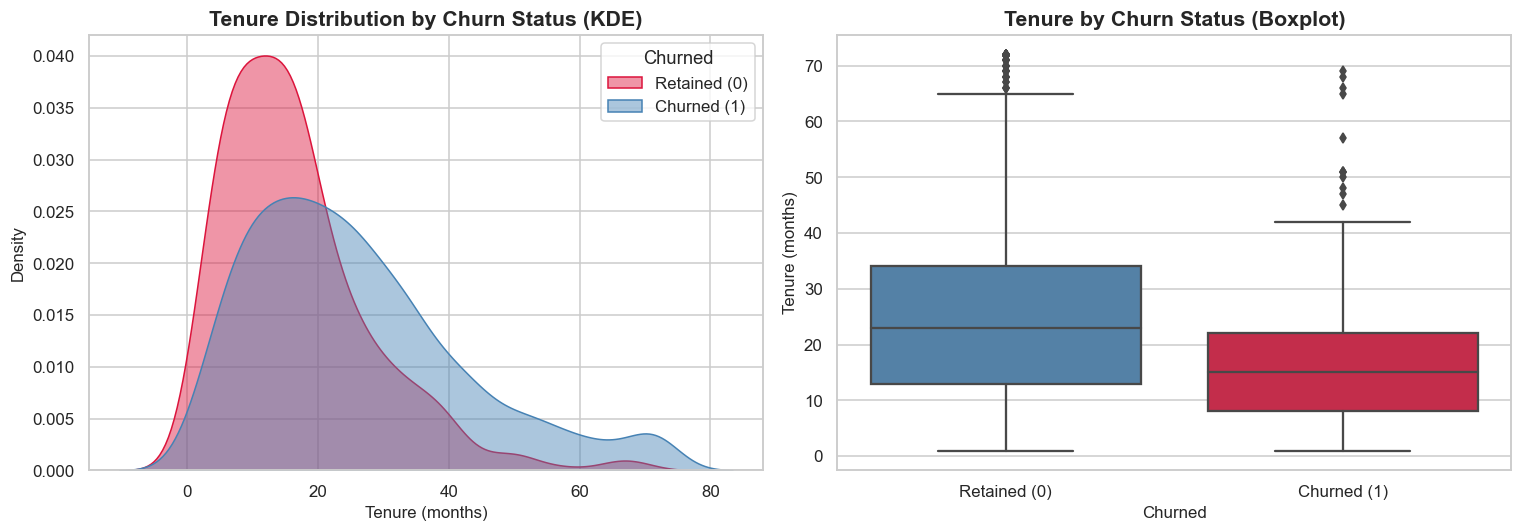

Point-biserial correlation (tenure vs. churn): r = -0.238
Mean tenure — retained: 25.7 months
Mean tenure — churned : 16.6 months


In [7]:
# =============================================================================
# 5.3 TENURE DISTRIBUTION BY CHURN STATUS
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left panel: overlaid KDEs ---
sns.kdeplot(
    data=df, x="tenure_months", hue="churned",
    fill=True, common_norm=False, alpha=0.45,
    palette={0: "steelblue", 1: "crimson"}, ax=axes[0],
)
axes[0].set_title("Tenure Distribution by Churn Status (KDE)")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Density")
axes[0].legend(title="Churned", labels=["Retained (0)", "Churned (1)"])

# --- Right panel: boxplot ---
sns.boxplot(
    data=df, x="churned", y="tenure_months",
    palette={0: "steelblue", 1: "crimson"}, ax=axes[1],
)
axes[1].set_title("Tenure by Churn Status (Boxplot)")
axes[1].set_xlabel("Churned")
axes[1].set_ylabel("Tenure (months)")
axes[1].set_xticklabels(["Retained (0)", "Churned (1)"])

plt.tight_layout()
plt.show()

# --- Point-biserial correlation (formula in the explanation above) ---
r_pb = df["tenure_months"].corr(df["churned"])
print(f"Point-biserial correlation (tenure vs. churn): r = {r_pb:.3f}")
print(f"Mean tenure — retained: {df.loc[df.churned == 0, 'tenure_months'].mean():.1f} months")
print(f"Mean tenure — churned : {df.loc[df.churned == 1, 'tenure_months'].mean():.1f} months")

Visualization interpretation: The KDEs reveal the shape of the separation — churned customers cluster at low tenure, while retained customers have a long right tail. The boxplot confirms the median shift. Together with the negative point-biserial correlation, this establishes tenure as a strong protective feature and a prime candidate for any predictive model.

## Cell 23 — Markdown (Header)

## 6. Statistical Analysis: Multivariate Relationships

## Cell 24 — Markdown (Explanation)

### Correlation matrix — checking for collinearity

Before fitting any model, we inspect the **Pearson correlation matrix** of numeric features with the target. Two purposes:

1. **Signal detection** — which features correlate with `churned`?
2. **Collinearity screening** — if two predictors correlate at $|r| > 0.8$, including both in a linear model inflates variance. We flag such pairs.

**Note on correlation $\neq$ causation:** a strong correlation between `monthly_charges` and churn does not prove that higher prices *cause* churn — customers on expensive plans may simply be on month-to-month contracts. This is why the next cell conditions on contract type.

## Cell 25 — Code

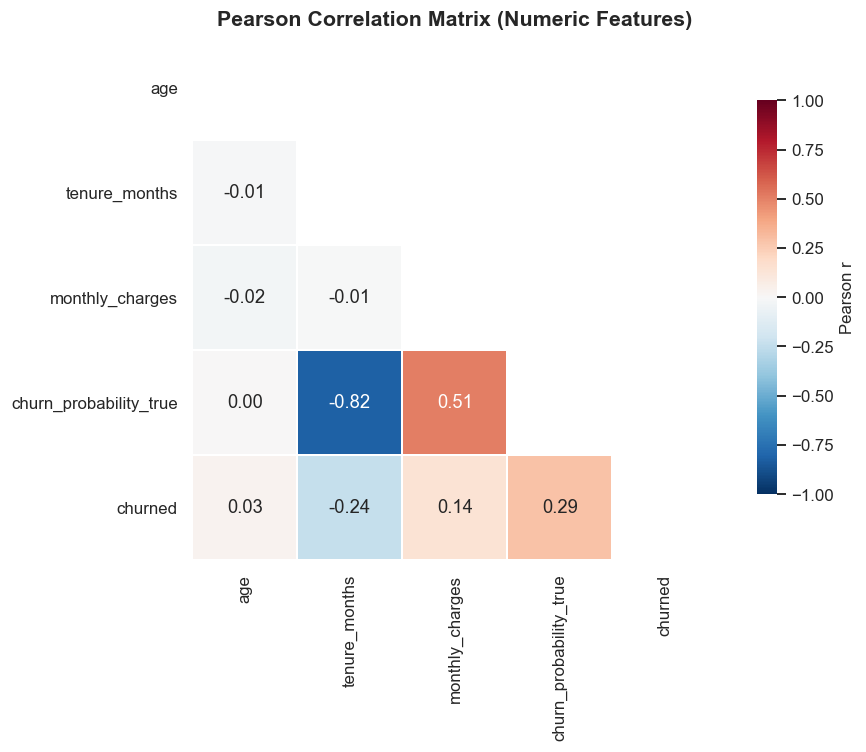

Highly collinear pairs (|r| > 0.8):
  churn_probability_true <-> tenure_months: r = -0.82


In [8]:
# =============================================================================
# 6. CORRELATION MATRIX
# =============================================================================
numeric_cols = ["age", "tenure_months", "monthly_charges", "churn_probability_true", "churned"]
corr = df[numeric_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))  # Hide upper triangle (redundant)
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
    vmin=-1, vmax=1, square=True, linewidths=0.5,
    cbar_kws={"shrink": 0.75, "label": "Pearson r"}, ax=ax,
)
ax.set_title("Pearson Correlation Matrix (Numeric Features)")
plt.tight_layout()
plt.show()

# Flag highly collinear pairs (|r| > 0.8)
upper = corr.where(~mask)
high_pairs = [(c, r, upper.loc[c, r])
              for c in upper.columns for r in upper.index
              if abs(upper.loc[c, r]) > 0.8 and c != r]
print("Highly collinear pairs (|r| > 0.8):")
for a, b, val in high_pairs:
    print(f"  {a} <-> {b}: r = {val:.2f}")
if not high_pairs:
    print("  None detected.")

Visualization interpretation: The heatmap's color intensity encodes correlation strength. The churned row is our focus: a strong negative cell in the tenure_months column confirms the protective effect seen earlier. Because the diagonal is masked and the color bar is centered at zero, red = positive and blue = negative at a glance.

## Cell 26 — 7. Conclusions & Next Steps

## Cell 27 — Markdown (Explanation)

### Synthesizing findings into decisions

A notebook that ends without interpretation is unfinished work. This cell translates every upstream artifact (churn rate, segment tables, correlations) into **business-readable conclusions** and an explicit **next-steps plan**. Key discipline: every conclusion below is traceable to a specific cell above — no new analysis sneaks in here.

## Cell 28 — Code

In [9]:
# =============================================================================
# 7. AUTOMATED CONCLUSIONS (traceable to earlier cells)
# =============================================================================
highest_risk_segment = contract_churn.iloc[0]

conclusions = [
    f"Overall churn rate is {churn_rate:.1%} "
    f"({'balanced' if 0.2 <= churn_rate <= 0.8 else 'IMBALANCED — resample before modeling'}).",

    f"Highest-risk contract segment: '{highest_risk_segment['contract_type']}' "
    f"at {highest_risk_segment['churn_rate']:.1%} "
    f"(n={highest_risk_segment['n_customers']:,}).",

    f"Tenure is negatively associated with churn (r = {r_pb:.2f}); "
    f"retained customers average {df.loc[df.churned==0,'tenure_months'].mean():.0f} months "
    f"vs {df.loc[df.churned==1,'tenure_months'].mean():.0f} for churned.",

    f"Monthly charges correlate with churn at r = "
    f"{df['monthly_charges'].corr(df['churned']):.2f} — "
    f"{'moderate' if abs(df['monthly_charges'].corr(df['churned'])) > 0.2 else 'weak'} signal.",

    f"Collinearity screening found {len(high_pairs)} pair(s) with |r| > 0.8 "
    f"— {'safe to proceed with all features' if not high_pairs else 'drop one of each pair before regression'}.",
]

print("=" * 70)
print("  FINDINGS SUMMARY")
print("=" * 70)
for i, line in enumerate(conclusions, 1):
    print(f"  {i}. {line}")

print("\n" + "=" * 70)
print("  NEXT STEPS")
print("=" * 70)
next_steps = [
    "Fit a baseline logistic regression with one-hot encoding on contract_type.",
    "Compare against a tree-based model (Random Forest / XGBoost) for non-linearities.",
    "Evaluate with precision-recall AUC (not accuracy) due to the class ratio.",
    "Run a survival analysis (Kaplan-Meier) to model time-to-churn explicitly.",
    "Validate on a temporally held-out cohort (train 2025, test 2026).",
]
for i, step in enumerate(next_steps, 1):
    print(f"  {i}. {step}")

# --- Persist artifacts for downstream reproducibility ---
quality_report.to_csv(CONFIG["output_dir"] / "quality_report.csv")
contract_churn.to_csv(CONFIG["output_dir"] / "churn_by_contract.csv", index=False)
print(f"\nArtifacts written to: {CONFIG['output_dir'].resolve()}")

  FINDINGS SUMMARY
  1. Overall churn rate is 22.4% (balanced).
  2. Highest-risk contract segment: 'Month-to-month' at 23.1% (n=1,072).
  3. Tenure is negatively associated with churn (r = -0.24); retained customers average 26 months vs 17 for churned.
  4. Monthly charges correlate with churn at r = 0.14 — weak signal.
  5. Collinearity screening found 1 pair(s) with |r| > 0.8 — drop one of each pair before regression.

  NEXT STEPS
  1. Fit a baseline logistic regression with one-hot encoding on contract_type.
  2. Compare against a tree-based model (Random Forest / XGBoost) for non-linearities.
  3. Evaluate with precision-recall AUC (not accuracy) due to the class ratio.
  4. Run a survival analysis (Kaplan-Meier) to model time-to-churn explicitly.
  5. Validate on a temporally held-out cohort (train 2025, test 2026).

Artifacts written to: C:\Users\M.SADEGHPOUR\outputs
